# Notebook 2: Entrenamiento y optimización de hiperparámetros
Objetivo: entrenar un clasificador de fraude, optimizar sus hiperparámetros y registrar todo en MLflow (DagsHub).
Regla: el conjunto de test no se usa durante la optimización.

In [2]:
import os  # variables de entorno
import numpy as np  # cálculo numérico
import pandas as pd  # tablas
import mlflow  # registro de experimentos
import lightgbm as lgb  # algoritmo de gradient boosting
from dotenv import load_dotenv  # lee el archivo .env
from sklearn.metrics import (
    average_precision_score,  # AUPRC, nuestra métrica principal
    roc_auc_score,  # AUC-ROC
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,  # curva para buscar el mejor umbral
)

load_dotenv("../.env")  # ruta explícita: el .env está en la raíz y el notebook en notebooks/
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])  # apuntamos MLflow a DagsHub
mlflow.set_experiment("fraude-paysim")  # experimento donde se guardarán los runs

SEMILLA = 42  # semilla fija para que los resultados sean reproducibles
OBJETIVO = "isFraud"  # variable a predecir
FEATURES = [
    "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "errorBalanceOrig", "errorBalanceDest", "origenVacio", "destinoVacio",
    "hora_dia", "es_transfer",
]  # las mismas variables definidas en el Notebook 1

2026/10/16 22:43:48 INFO mlflow.tracking.fluent: Experiment with name 'fraude-paysim' does not exist. Creating a new experiment.


In [3]:
train = pd.read_parquet("../data/processed/full/train.parquet")  # datos de entrenamiento (steps 1-400)

fit = train[train["step"] <= 300]  # parte con la que se entrena durante la optimización
val = train[train["step"] > 300]  # parte para validar (el "futuro" dentro del train)

X_fit, y_fit = fit[FEATURES], fit[OBJETIVO]  # X = variables, y = objetivo
X_val, y_val = val[FEATURES], val[OBJETIVO]

print(f"fit: {len(fit):,} filas, {y_fit.sum():,} fraudes ({y_fit.mean()*100:.2f}%)")
print(f"val: {len(val):,} filas, {y_val.sum():,} fraudes ({y_val.mean()*100:.2f}%)")

fit: 1,780,544 filas, 3,401 fraudes (0.19%)
val: 748,992 filas, 1,076 fraudes (0.14%)


In [6]:
def evaluar(y_true, y_score, umbral):
    """Calcula las métricas de clasificación para un umbral dado.

    Args:
        y_true: etiquetas reales (0 = normal, 1 = fraude).
        y_score: puntaje crudo del modelo (log-odds), no probabilidad.
        umbral: puntaje mínimo para clasificar como fraude.

    Returns:
        Diccionario con AUPRC, ROC-AUC, precision, recall, F1 y prevalencia.
    """
    y_pred = (y_score >= umbral).astype(int)  # decisión 0/1 según el umbral
    return {
        "auprc": average_precision_score(y_true, y_score),  # no depende del umbral
        "roc_auc": roc_auc_score(y_true, y_score),  # no depende del umbral
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "prevalencia": float(np.mean(y_true)),  # AUPRC de un modelo al azar
    }


def mejor_umbral_f1(y_true, y_score):
    """Busca el umbral de puntaje que maximiza el F1.

    Args:
        y_true: etiquetas reales.
        y_score: puntajes predichos.

    Returns:
        El umbral (float) con mayor F1.
    """
    precision, recall, umbrales = precision_recall_curve(y_true, y_score)  # un punto por umbral posible
    f1 = 2 * precision * recall / (precision + recall + 1e-12)  # F1 en cada punto
    return float(umbrales[np.argmax(f1[:-1])])  # el último punto no tiene umbral

In [7]:
peso_fraude = (y_fit == 0).sum() / (y_fit == 1).sum()  # normales por cada fraude (≈523)

params_base = {
    "n_estimators": 100,  # menos árboles: evita la saturación
    "learning_rate": 0.1,  # valor por defecto de LightGBM
    "num_leaves": 31,  # valor por defecto
    "scale_pos_weight": float(np.sqrt(peso_fraude)),  # peso moderado (≈23) en vez de 523
    "random_state": SEMILLA,
    "n_jobs": -1,
    "verbose": -1,
}

with mlflow.start_run(run_name="lgbm_baseline_v2"):
    modelo = lgb.LGBMClassifier(**params_base)
    modelo.fit(X_fit, y_fit)  # entrena

    puntaje_val = modelo.predict(X_val, raw_score=True)  # log-odds, sin sigmoide: no se satura
    umbral = mejor_umbral_f1(y_val, puntaje_val)  # umbral elegido en validación
    metricas = evaluar(y_val, puntaje_val, umbral)

    mlflow.log_params(params_base)
    mlflow.log_param("umbral", umbral)
    mlflow.log_metrics({f"val_{k}": v for k, v in metricas.items()})

print(f"Peso de fraude usado: {params_base['scale_pos_weight']:.1f}")
print(f"Umbral elegido (log-odds): {umbral:.4f}")
for nombre, valor in metricas.items():
    print(f"{nombre}: {valor:.4f}")

🏃 View run lgbm_baseline_v2 at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1/runs/dfa6363775fc4a9c973983d155421060
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1
Peso de fraude usado: 22.9
Umbral elegido (log-odds): 3898429.6486
auprc: 0.4780
roc_auc: 0.7225
precision: 0.9544
recall: 0.3699
f1: 0.5332
prevalencia: 0.0014


In [8]:
import matplotlib.pyplot as plt  # gráfica de convergencia

# Espacio de búsqueda: nombre: (mínimo, máximo, tipo de escala)
ESPACIO = {
    "n_estimators": (50, 300, "int"),  # número de árboles
    "learning_rate": (0.01, 0.3, "log"),  # escala log: importan los órdenes de magnitud
    "num_leaves": (8, 128, "int"),  # complejidad de cada árbol
    "min_child_samples": (5, 200, "int"),  # mínimo de filas por hoja
    "colsample_bytree": (0.5, 1.0, "float"),  # fracción de variables por árbol
    "scale_pos_weight": (1, 523, "log"),  # peso de la clase fraude
    "reg_lambda": (0.001, 10, "log"),  # regularización L2
}
N_GENES = len(ESPACIO)  # un gen por hiperparámetro

estado = {"evals": 0, "cache": {}, "mejor_hist": [], "mejor": -1.0}  # contadores globales del GA


def decodificar(ind):
    """Convierte un individuo (genes en [0, 1]) en un diccionario de hiperparámetros."""
    params = {}
    for gen, (nombre, (bajo, alto, tipo)) in zip(ind, ESPACIO.items()):
        if tipo == "log":
            valor = np.exp(np.log(bajo) + gen * (np.log(alto) - np.log(bajo)))  # interpolación en escala log
        else:
            valor = bajo + gen * (alto - bajo)  # interpolación lineal
        params[nombre] = int(round(valor)) if tipo == "int" else float(valor)
    return params


def aptitud(ind, ciclo, iteracion):
    """Evalúa un individuo: entrena LightGBM y devuelve el AUPRC en validación.

    Args:
        ind: vector de genes en [0, 1].
        ciclo: ciclo externo actual (solo para registrar).
        iteracion: iteración interna actual (solo para registrar).

    Returns:
        AUPRC de validación (float). Si el individuo ya se evaluó, devuelve el valor guardado.
    """
    clave = tuple(np.round(ind, 4))  # identifica al individuo
    if clave in estado["cache"]:
        return estado["cache"][clave]  # no reentrena individuos repetidos (ahorra tiempo)

    params = decodificar(ind)
    estado["evals"] += 1
    with mlflow.start_run(run_name=f"eval_{estado['evals']:03d}", nested=True):  # run hijo del run padre
        mlflow.log_params(params)
        mlflow.log_params({"ciclo": ciclo, "iteracion": iteracion})
        modelo = lgb.LGBMClassifier(**params, random_state=SEMILLA, n_jobs=-1, verbose=-1)
        modelo.fit(X_fit, y_fit)
        puntaje = modelo.predict(X_val, raw_score=True)  # log-odds, sin saturación
        auprc = float(average_precision_score(y_val, puntaje))
        mlflow.log_metric("val_auprc", auprc)

    estado["cache"][clave] = auprc
    estado["mejor"] = max(estado["mejor"], auprc)
    estado["mejor_hist"].append(estado["mejor"])  # curva de convergencia
    return auprc


def diversidad(poblacion, i_mejor):
    """Distancia media (en [0, 1]) entre los individuos y el mejor."""
    return float(np.mean(np.abs(poblacion - poblacion[i_mejor])))


def torneo(poblacion, aptitudes, rng):
    """Elige 2 individuos al azar y devuelve el de mayor aptitud (Crossing)."""
    a, b = rng.choice(len(poblacion), size=2, replace=False)
    return poblacion[a] if aptitudes[a] >= aptitudes[b] else poblacion[b]


def cruce_blx(p1, p2, rng, alfa=0.3):
    """Recombinación BLX-alfa: cada gen del hijo se sortea entre los de los padres, ampliado un 30%."""
    bajo, alto = np.minimum(p1, p2), np.maximum(p1, p2)
    d = alto - bajo  # distancia entre los genes de los padres
    return np.clip(rng.uniform(bajo - alfa * d, alto + alfa * d), 0, 1)  # recorta a [0, 1]


def micro_ga(tam_pob=5, max_evals=40, umbral_diversidad=0.15, paciencia_externa=2,
             p_deriva=0.2, sigma_deriva=0.05, max_iter_interna=15, semilla=SEMILLA):
    """Micro algoritmo genético para optimizar hiperparámetros.

    Args:
        tam_pob: tamaño de la población (pequeño, de ahí el "micro").
        max_evals: presupuesto aproximado de entrenamientos.
        umbral_diversidad: bajo este valor se declara convergencia nominal.
        paciencia_externa: ciclos externos sin mejora antes de terminar.
        p_deriva: probabilidad de deriva genética por individuo.
        sigma_deriva: magnitud de la perturbación de la deriva.
        max_iter_interna: tope de iteraciones por ciclo interno.
        semilla: semilla del generador aleatorio.

    Returns:
        (mejor individuo, mejor aptitud, bitácora de iteraciones).
    """
    rng = np.random.default_rng(semilla)
    poblacion = rng.random((tam_pob, N_GENES))  # Random Population
    mejor_ind, mejor_fit = None, -1.0
    ciclo, estancados, bitacora = 0, 0, []

    while estado["evals"] < max_evals:  # ciclo externo
        ciclo += 1
        for it in range(1, max_iter_interna + 1):  # ciclo interno
            aptitudes = np.array([aptitud(i, ciclo, it) for i in poblacion])  # Aptitude Evaluation
            if estado["evals"] >= max_evals:
                break
            hijos = np.array([  # Crossing + Recombination
                cruce_blx(torneo(poblacion, aptitudes, rng), torneo(poblacion, aptitudes, rng), rng)
                for _ in range(tam_pob - 1)
            ])
            aptitudes_h = np.array([aptitud(h, ciclo, it) for h in hijos])  # Re-evaluation

            todos = np.vstack([poblacion, hijos])  # padres + hijos
            todas_f = np.concatenate([aptitudes, aptitudes_h])
            orden = np.argsort(-todas_f)[:tam_pob]  # Natural Selection: los mejores sobreviven
            poblacion, aptitudes = todos[orden], todas_f[orden]

            for k in range(1, tam_pob):  # Genetic Drift (el mejor, en la posición 0, no se toca)
                if rng.random() < p_deriva:
                    poblacion[k] = np.clip(poblacion[k] + rng.normal(0, sigma_deriva, N_GENES), 0, 1)

            div = diversidad(poblacion, 0)  # Autoregulation: población fija y dentro de [0, 1]
            bitacora.append((ciclo, it, float(aptitudes[0]), div))
            if div < umbral_diversidad or estado["evals"] >= max_evals:
                break  # Nominal Convergence: sale del ciclo interno

        i_best = int(np.argmax(aptitudes))
        if aptitudes[i_best] > mejor_fit + 1e-4:
            estancados = 0  # hubo mejora real
        else:
            estancados += 1
        if aptitudes[i_best] > mejor_fit:
            mejor_fit, mejor_ind = float(aptitudes[i_best]), poblacion[i_best].copy()
        print(f"Ciclo {ciclo}: mejor ciclo={aptitudes[i_best]:.4f} | mejor global={mejor_fit:.4f} | "
              f"evals={estado['evals']} | ciclos sin mejora={estancados}")

        if estancados >= paciencia_externa:
            break  # General Convergence
        poblacion = np.vstack([mejor_ind, rng.random((tam_pob - 1, N_GENES))])  # Elitism + nueva población al azar
    return mejor_ind, mejor_fit, bitacora  # X* Solution

🏃 View run eval_001 at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1/runs/7bcf18a8dc7b4328a554f69fbf2b84c3
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1
🏃 View run eval_002 at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1/runs/153ddd928e7f471e92ce0fd64bb883c3
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1
🏃 View run eval_003 at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1/runs/cf090036f7174188b834574b9d95b86e
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1
🏃 View run eval_004 at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1/runs/e397b5e8f04349a5b005492a0130e4d7
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1
🏃 View run eval_005 at: https://

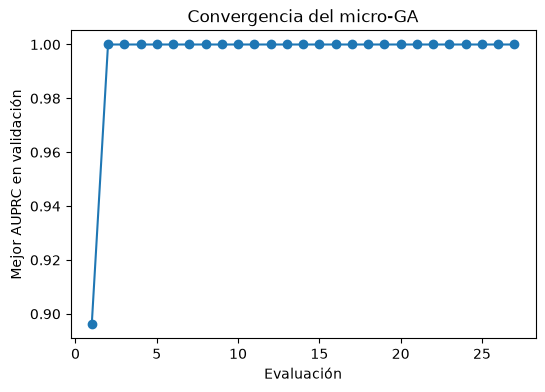

🏃 View run microGA_lgbm at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1/runs/5f34c45839c143058186408dd2e5b5f2
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1

Mejores hiperparámetros (X*):
  n_estimators: 145
  learning_rate: 0.027884952910689702
  num_leaves: 84
  min_child_samples: 76
  colsample_bytree: 0.5438249596580504
  scale_pos_weight: 2.09314466081024
  reg_lambda: 7.040291774325846

AUPRC validación: baseline=0.4780 -> micro-GA=1.0000


In [9]:
estado.update({"evals": 0, "cache": {}, "mejor_hist": [], "mejor": -1.0})  # reinicia los contadores
MAX_EVALS = 40  # presupuesto de entrenamientos

with mlflow.start_run(run_name="microGA_lgbm"):  # run padre: agrupa todas las evaluaciones
    mlflow.log_params({
        "algoritmo": "micro-GA", "tam_pob": 5, "max_evals": MAX_EVALS,
        "umbral_diversidad": 0.15, "paciencia_externa": 2, "p_deriva": 0.2,
    })
    mejor_ind, mejor_fit, bitacora = micro_ga(max_evals=MAX_EVALS)
    mejores_params = decodificar(mejor_ind)  # X*: los mejores hiperparámetros
    mlflow.log_params({f"mejor_{k}": v for k, v in mejores_params.items()})
    mlflow.log_metric("mejor_val_auprc", mejor_fit)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(range(1, len(estado["mejor_hist"]) + 1), estado["mejor_hist"], marker="o")  # mejor AUPRC acumulado
    ax.set_xlabel("Evaluación")
    ax.set_ylabel("Mejor AUPRC en validación")
    ax.set_title("Convergencia del micro-GA")
    mlflow.log_figure(fig, "convergencia_microGA.png")  # sube la gráfica como artefacto a DagsHub
    plt.show()

print("\nMejores hiperparámetros (X*):")
for k, v in mejores_params.items():
    print(f"  {k}: {v}")
print(f"\nAUPRC validación: baseline={metricas['auprc']:.4f} -> micro-GA={mejor_fit:.4f}")

In [10]:
evals = pd.DataFrame([
    {**decodificar(np.array(clave)), "val_auprc": valor}  # hiperparámetros decodificados + su aptitud
    for clave, valor in estado["cache"].items()  # la caché guarda todas las evaluaciones del GA
])

n_techo = (evals["val_auprc"] >= 0.999).sum()  # cuántas llegaron al techo
print(f"Evaluaciones: {len(evals)} | con AUPRC >= 0.999: {n_techo}")

print("\nTop 5 configuraciones:")
print(evals.sort_values("val_auprc", ascending=False).head(5).round(4).to_string())

print("\nCorrelación de Spearman entre cada hiperparámetro y el AUPRC:")
print(evals.corr(method="spearman")["val_auprc"].drop("val_auprc").round(2).sort_values())

evals.to_csv("../reports/evaluaciones_microGA.csv", index=False)  # evidencia para el README

Evaluaciones: 27 | con AUPRC >= 0.999: 16

Top 5 configuraciones:
    n_estimators  learning_rate  num_leaves  min_child_samples  colsample_bytree  scale_pos_weight  reg_lambda  val_auprc
7            145         0.0279          84                 76            0.5438            2.0931      7.0404        1.0
24           205         0.0278          86                 52            0.5898            1.8056     10.0000        1.0
18           191         0.0272          56                 75            0.9748           51.8274      2.1439        1.0
15           199         0.0175          82                 77            0.6688            1.2821      6.1546        1.0
25           194         0.0279          83                 68            0.5370            2.0503      6.6435        1.0

Correlación de Spearman entre cada hiperparámetro y el AUPRC:
scale_pos_weight    -0.55
learning_rate       -0.53
min_child_samples   -0.31
num_leaves          -0.05
colsample_bytree     0.01
n_estimat

       auprc  roc_auc  precision  recall      f1  prevalencia  lift_vs_azar
val   1.0000      1.0     1.0000  1.0000  1.0000       0.0014      696.0892
test  0.9999      1.0     0.9995  0.9995  0.9995       0.0108       92.3682
prod  1.0000      1.0     1.0000  0.9994  0.9997       0.0367       27.2184

Umbral (log-odds): -2.1456


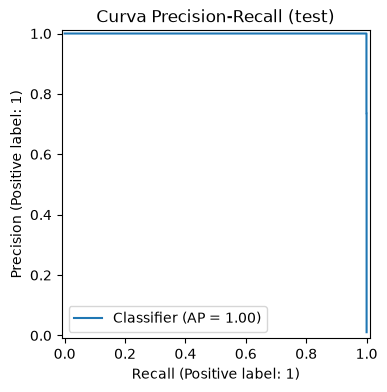

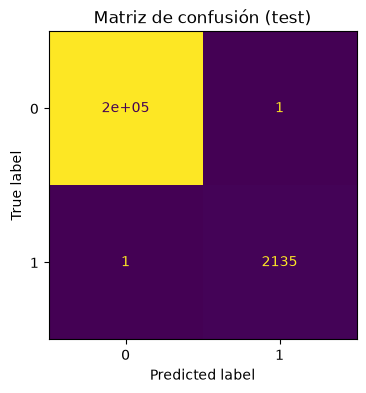

2026/10/16 23:51:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
Successfully registered model 'fraude-paysim-lgbm'.
2026/10/16 23:51:47 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: fraude-paysim-lgbm, version 1
Created version '1' of model 'fraude-paysim-lgbm'.


🏃 View run modelo_final_microGA at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1/runs/27fa4012f36a4a8c83acc95e4cf5e95d
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/1
Modelo 'fraude-paysim-lgbm' versión 1 con alias 'produccion'


In [11]:
import mlflow.lightgbm  # soporte de MLflow para guardar modelos LightGBM
from mlflow import MlflowClient  # cliente para el Model Registry
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay  # gráficas de evaluación

test = pd.read_parquet("../data/processed/full/test.parquet")  # steps 401-600: métricas offline
prod = pd.read_parquet("../data/processed/full/prod.parquet")  # steps 601-743: métricas online


def umbral_con_margen(y_true, y_score):
    """Umbral que maximiza el F1, movido al punto medio con el puntaje inmediato inferior.

    Args:
        y_true: etiquetas reales (array de numpy).
        y_score: puntajes crudos del modelo (array de numpy).

    Returns:
        Umbral (float) con margen, para que no quede justo en el borde.
    """
    u = mejor_umbral_f1(y_true, y_score)  # umbral de máximo F1
    u_previo = y_score[y_score < u].max()  # mayor puntaje que queda por debajo
    return float((u + u_previo) / 2)  # punto medio entre ambos


modelo_final = lgb.LGBMClassifier(**mejores_params, random_state=SEMILLA, n_jobs=-1, verbose=-1)  # X* del GA
modelo_final.fit(X_fit, y_fit)  # entrena con steps 1-300

puntaje_val = modelo_final.predict(X_val, raw_score=True)
umbral_final = umbral_con_margen(y_val.values, puntaje_val)  # el umbral se elige SOLO con validación

resultados = {}  # nombre del conjunto: (puntajes, métricas)
for nombre, datos in {"val": val, "test": test, "prod": prod}.items():
    puntaje = modelo_final.predict(datos[FEATURES], raw_score=True)
    resultados[nombre] = (puntaje, evaluar(datos[OBJETIVO].values, puntaje, umbral_final))

tabla = pd.DataFrame({k: v[1] for k, v in resultados.items()}).T  # una fila por conjunto
tabla["lift_vs_azar"] = tabla["auprc"] / tabla["prevalencia"]  # cuántas veces mejor que el azar
print(tabla.round(4))
print(f"\nUmbral (log-odds): {umbral_final:.4f}")

y_test, s_test = test[OBJETIVO].values, resultados["test"][0]
fig1, ax1 = plt.subplots(figsize=(5, 4))
PrecisionRecallDisplay.from_predictions(y_test, s_test, ax=ax1)  # curva precision-recall
ax1.set_title("Curva Precision-Recall (test)")
fig2, ax2 = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (s_test >= umbral_final).astype(int), ax=ax2, colorbar=False)
ax2.set_title("Matriz de confusión (test)")
plt.show()

NOMBRE_MODELO = "fraude-paysim-lgbm"
with mlflow.start_run(run_name="modelo_final_microGA"):
    mlflow.log_params(mejores_params)
    mlflow.log_param("umbral_log_odds", umbral_final)  # la app de monitoreo leerá el umbral de aquí
    mlflow.log_param("entrenado_con", "steps 1-300")
    for nombre, (_, met) in resultados.items():
        mlflow.log_metrics({f"{nombre}_{k}": v for k, v in met.items()})  # val_, test_ y prod_
    mlflow.log_figure(fig1, "curva_pr_test.png")  # artefacto
    mlflow.log_figure(fig2, "matriz_confusion_test.png")  # artefacto
    mlflow.lightgbm.log_model(modelo_final, artifact_path="modelo", registered_model_name=NOMBRE_MODELO)  # guarda y registra

cliente = MlflowClient()
versiones = cliente.search_model_versions(f"name='{NOMBRE_MODELO}'")  # todas las versiones del modelo
ultima = max(int(v.version) for v in versiones)  # la más reciente
cliente.set_registered_model_alias(NOMBRE_MODELO, "produccion", ultima)  # la marca como modelo productivo
print(f"Modelo '{NOMBRE_MODELO}' versión {ultima} con alias 'produccion'")